# Lab 9 · Gyroscope parameters

**240048** 
· Option A: sine and square-wave turns, followed by rest.
The QRS logs `gz_cal` in millidegrees per second. This is the processed rate channel. The raw gyro channel needed to fit a raw-to-rate conversion is missing.

The gyro clock advances in 256 μs steps in this log. After conversion, its elapsed time agrees with the program clock to within about 0.1 s. 

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

file = Path('lab9_gyro.csv')
if not file.exists():
    from google.colab import files
    files.upload()

log = pd.read_csv(file)
log['t'] = (log.t_us - log.t_us.iloc[0]) * 256e-6
log['rate'] = log.gz_cal / 1000
clock = (log.t_ms - log.t_ms.iloc[0]) / 1000
print(f'Maximum clock difference: {abs(log.t - clock).max():.3f} s')
for phase, part in log.groupby('phase', sort=False):
    duration = part.t.iloc[-1] - part.t.iloc[0]
    interval = np.median(np.diff(part.t)) * 1000
    print(f'{phase:6} {len(part):4} samples, {duration:6.2f} s, median step {interval:.0f} ms')

def integrate(rate, t):
    # Average consecutive rates, then multiply by the actual time step.
    return np.r_[0, np.cumsum((rate[:-1] + rate[1:]) / 2 * np.diff(t))]


Maximum clock difference: 0.100 s
static 2502 samples, 179.91 s, median step 73 ms
sin     311 samples,  35.92 s, median step 115 ms
rect    317 samples,  35.87 s, median step 115 ms
rest     28 samples,   2.98 s, median step 104 ms


## Bias and drift

I use the median of the first 10 s for calibration. It is less sensitive to spikes, and the median is flat from 5 to 30 s in this log. The 30 s mean is the baseline.

30 s mean: 0.5756 ± 0.0038 °/s (standard error)
10 s median: 0.5680 °/s
Uncorrected heading slope: 32.78 °/min (bias × 60 = 34.08 °/min)


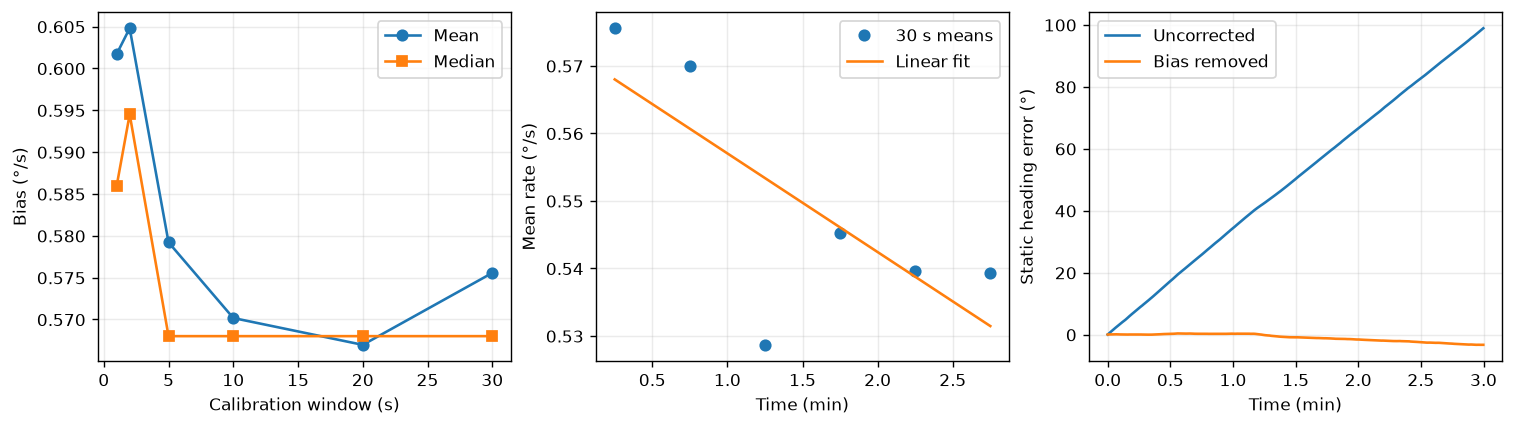

In [2]:
static = log[log.phase == 'static']
t = static.t.to_numpy()
rate = static.rate.to_numpy()
windows = [1, 2, 5, 10, 20, 30]
means = [rate[t <= seconds].mean() for seconds in windows]
medians = [np.median(rate[t <= seconds]) for seconds in windows]
first_30 = rate[t <= 30]
baseline = first_30.mean()
standard_error = first_30.std(ddof=1) / np.sqrt(len(first_30))

def calibrate_gyro(log):
    first_10 = log.t - log.t.iloc[0] <= 10
    return log.loc[first_10, 'rate'].median()

bias = calibrate_gyro(static)
window_mean = static.groupby(static.t // 30).rate.mean().to_numpy()
window_min = (np.arange(len(window_mean)) * 30 + 15) / 60
drift, intercept = np.polyfit(window_min, window_mean, 1)
angle_raw = integrate(rate, t)
angle_corrected = integrate(rate - bias, t)
heading_drift = np.polyfit(t / 60, angle_raw, 1)[0]
print(f'30 s mean: {baseline:.4f} ± {standard_error:.4f} °/s (standard error)')
print(f'10 s median: {bias:.4f} °/s')
print(f'Uncorrected heading slope: {heading_drift:.2f} °/min (bias × 60 = {bias*60:.2f} °/min)')

fig, ax = plt.subplots(1, 3, figsize=(12, 3.3), layout='constrained')
ax[0].plot(windows, means, 'o-', label='Mean')
ax[0].plot(windows, medians, 's-', label='Median')
ax[0].set(xlabel='Calibration window (s)', ylabel='Bias (°/s)')
ax[0].legend()
ax[1].plot(window_min, window_mean, 'o', label='30 s means')
ax[1].plot(window_min, drift * window_min + intercept, label='Linear fit')
ax[1].set(xlabel='Time (min)', ylabel='Mean rate (°/s)')
ax[1].legend()
ax[2].plot(t / 60, angle_raw, label='Uncorrected')
ax[2].plot(t / 60, angle_corrected, label='Bias removed')
ax[2].set(xlabel='Time (min)', ylabel='Static heading error (°)')
ax[2].legend()
for axis in ax:
    axis.grid(alpha=0.25)


## Resolution and noise

The minimum recorded step is for `gz_cal`. The histogram shows how the bias-corrected readings compare with a Gaussian.

Minimum output step: 0.008 °/s
Noise std: 0.0759 °/s; variance: 0.00575 (°/s)²
Samples beyond 3σ: 9 of 2502


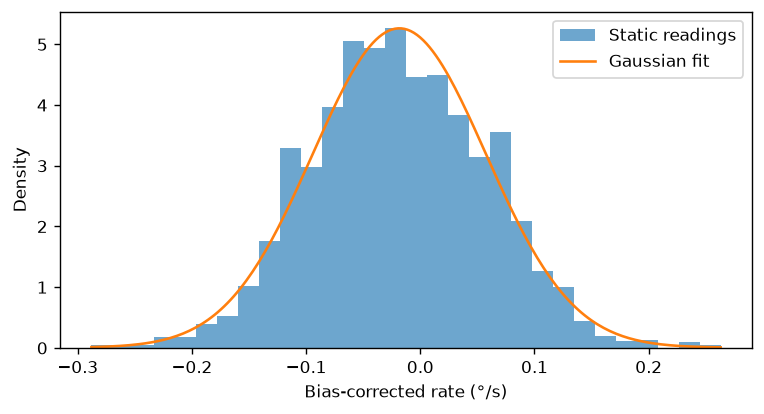

In [3]:
resolution = np.diff(np.unique(static.gz_cal)).min() / 1000
residual = rate - bias
sigma = residual.std(ddof=1)
x = np.linspace(residual.min(), residual.max(), 200)
gaussian = np.exp(-0.5 * ((x - residual.mean()) / sigma)**2) / (sigma * np.sqrt(2*np.pi))
outliers = np.count_nonzero(abs(residual - residual.mean()) > 3 * sigma)
print(f'Minimum output step: {resolution:.3f} °/s')
print(f'Noise std: {sigma:.4f} °/s; variance: {sigma**2:.5f} (°/s)²')
print(f'Samples beyond 3σ: {outliers} of {len(rate)}')

plt.figure(figsize=(6, 3.2), layout='constrained')
plt.hist(residual, bins=30, density=True, alpha=0.65, label='Static readings')
plt.plot(x, gaussian, label='Gaussian fit')
plt.xlabel('Bias-corrected rate (°/s)')
plt.ylabel('Density')
plt.legend()


## Rotation, clipping and scale

I use the earlier odometry settings provisionally: wheel radius 2.8 cm, track width 15.4 cm and encoder readings in degrees. The angle uses right minus left, with CCW positive. A positive correlation checks the gyro sign against that convention.

For scale, I fit angle changes separately in each direction and exclude clipped intervals and rates below 20°/s. The full angle plot includes clipping, so its fit is shown for comparison. The scale estimates depend on the wheel dimensions and can be affected by slip.

In [4]:
rotation = log[log.phase != 'static']
start = rotation.t.iloc[0]
tr = rotation.t.to_numpy() - start
gyro = rotation.rate.to_numpy()
wheel_radius, track_width = 2.8, 15.4  # cm
wheel_difference = (rotation.encR - rotation.encL).to_numpy()
enc_angle = (wheel_difference - wheel_difference[0]) * wheel_radius / track_width
gyro_angle = integrate(gyro - bias, tr)
unadjusted_angle = integrate(gyro, tr)
error = gyro_angle - enc_angle

dt = np.diff(tr)
enc_change = np.diff(enc_angle)
gyro_change = np.diff(gyro_angle)
enc_rate = enc_change / dt
gyro_mid = (gyro[1:] + gyro[:-1]) / 2
midtime = (tr[1:] + tr[:-1]) / 2
lower, upper = gyro.min(), gyro.max()
at_limit = (gyro == lower) | (gyro == upper)
clipped = at_limit[1:] | at_limit[:-1]
driving = rotation.phase.to_numpy()[1:] != 'rest'
high_power = abs(rotation.u.to_numpy()[1:]) == 100
gain = {}
for direction, sign in [('CCW', 1), ('CW', -1)]:
    valid = driving & ~clipped & (sign * enc_rate > 20)
    for band, mask in [('All', valid), ('Slow (<150)', valid & (abs(enc_rate) < 150)),
                       ('Fast (≥150)', valid & (abs(enc_rate) >= 150))]:
        x, y = enc_change[mask], gyro_change[mask]
        slope = (x @ y) / (x @ x)
        if band == 'All':
            gain[direction] = slope
        print(f'{direction} {band:12} {(slope-1)*100:+6.2f}%  ({len(x)} intervals)')
correlation = np.corrcoef(enc_rate, gyro_mid)[0, 1]
print(f'Rate correlation: {correlation:.3f}')
print(f'Observed limits: {lower:.3f}, {upper:.3f} °/s')


CCW All           +8.32%  (209 intervals)
CCW Slow (<150)  +17.66%  (156 intervals)
CCW Fast (≥150)   +1.11%  (53 intervals)
CW All           +7.23%  (197 intervals)
CW Slow (<150)  +17.81%  (138 intervals)
CW Fast (≥150)   +0.96%  (59 intervals)
Rate correlation: 0.973
Observed limits: -286.440, 286.685 °/s


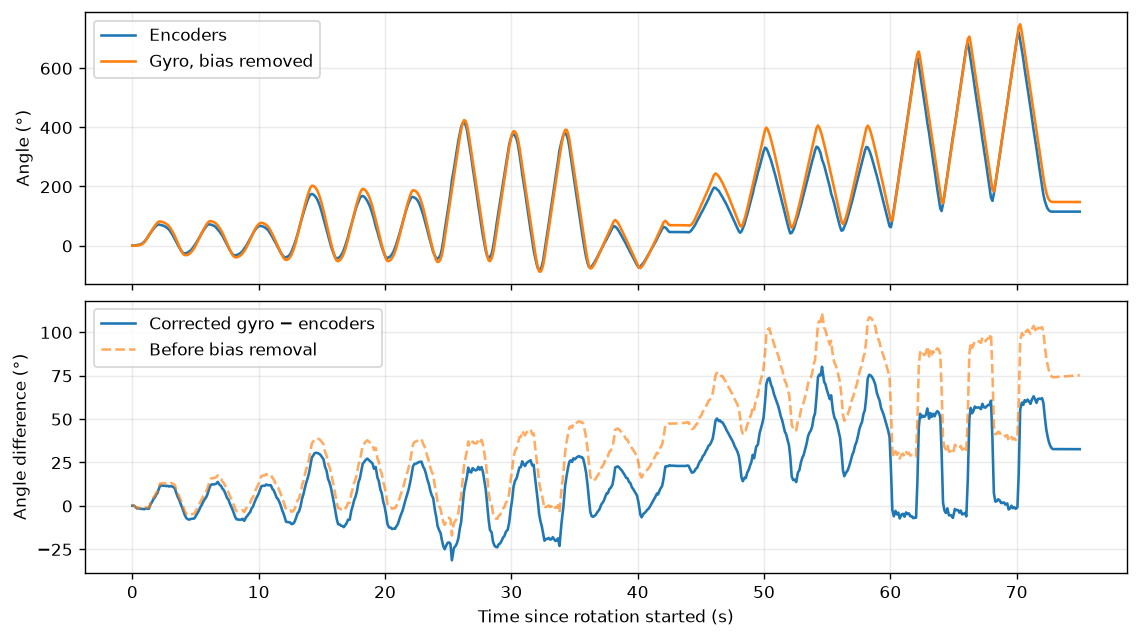

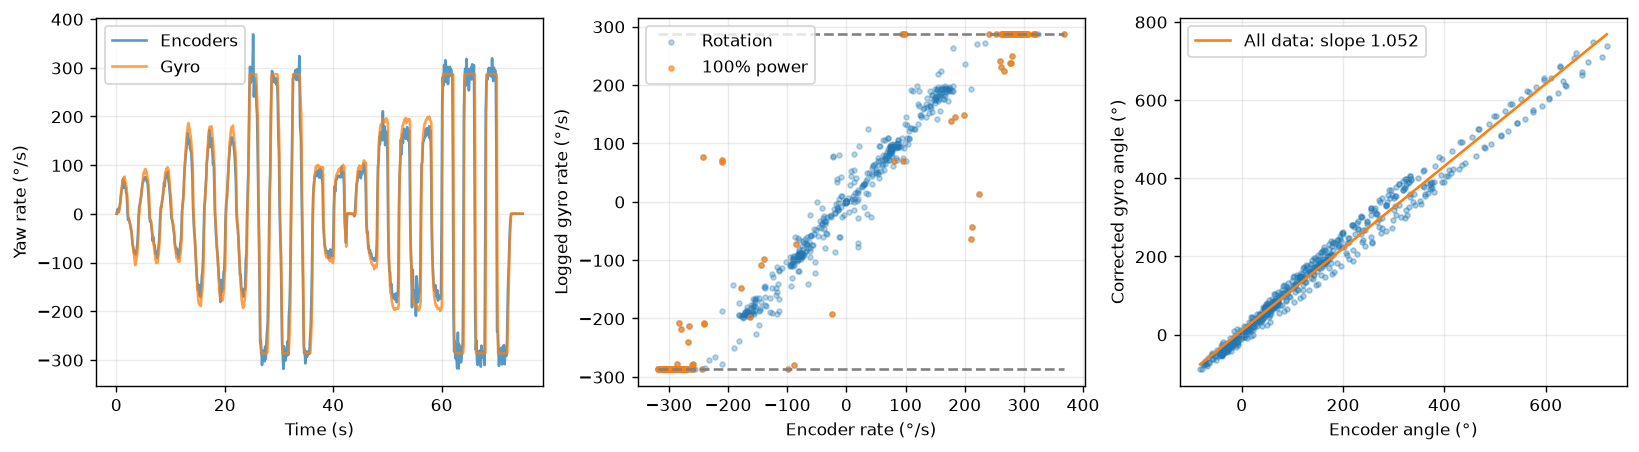

In [5]:
fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True, layout='constrained')
ax[0].plot(tr, enc_angle, label='Encoders')
ax[0].plot(tr, gyro_angle, label='Gyro, bias removed')
ax[0].set_ylabel('Angle (°)')
ax[1].plot(tr, error, label='Corrected gyro − encoders')
ax[1].plot(tr, unadjusted_angle - enc_angle, '--', label='Before bias removal', alpha=0.65)
ax[1].set(xlabel='Time since rotation started (s)', ylabel='Angle difference (°)')
for axis in ax:
    axis.grid(alpha=0.25)
    axis.legend()

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5), layout='constrained')
ax[0].plot(midtime, enc_rate, label='Encoders', alpha=0.75)
ax[0].plot(tr, gyro, label='Gyro', alpha=0.75)
ax[0].set(xlabel='Time (s)', ylabel='Yaw rate (°/s)')
ax[0].legend()
ax[1].scatter(enc_rate[driving], gyro_mid[driving], s=8, alpha=0.3, label='Rotation')
ax[1].scatter(enc_rate[high_power], gyro_mid[high_power], s=8, alpha=0.6, label='100% power')
ax[1].hlines([lower, upper], enc_rate.min(), enc_rate.max(), color='gray', linestyle='--')
ax[1].set(xlabel='Encoder rate (°/s)', ylabel='Logged gyro rate (°/s)')
ax[1].legend()
slope, offset = np.polyfit(enc_angle, gyro_angle, 1)
x = np.array([enc_angle.min(), enc_angle.max()])
ax[2].scatter(enc_angle, gyro_angle, s=8, alpha=0.35)
ax[2].plot(x, slope * x + offset, color='tab:orange', label=f'All data: slope {slope:.3f}')
ax[2].set(xlabel='Encoder angle (°)', ylabel='Corrected gyro angle (°)')
ax[2].legend()
for axis in ax:
    axis.grid(alpha=0.25)


## Simulated gyro

This model adds scale error, bias, drift and Gaussian noise, then applies the observed limits and output step. The encoder rate is the input for this comparison.

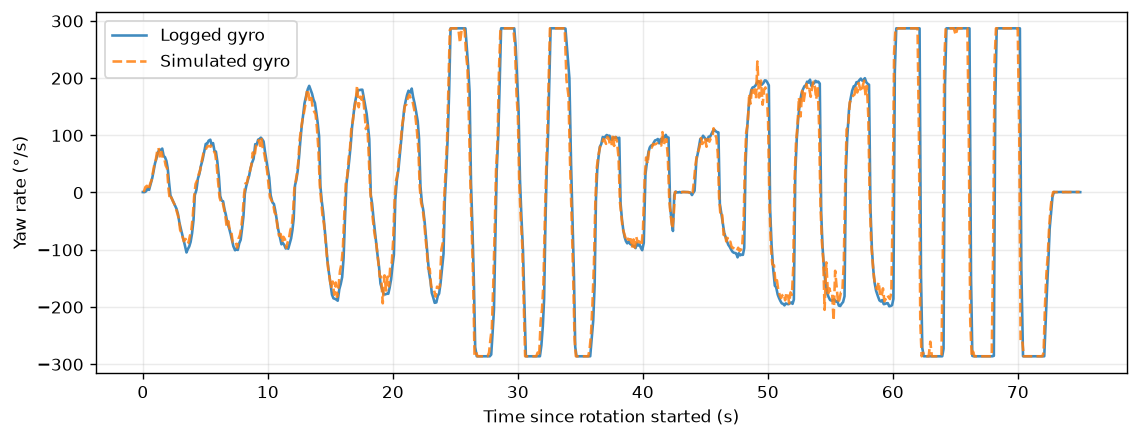

In [6]:
rng = np.random.default_rng(9)

def gyro_sim(omega_true, t):
    omega_true = np.asarray(omega_true)
    scale = np.where(omega_true >= 0, gain['CCW'], gain['CW'])
    noise = rng.normal(0, sigma, omega_true.shape)
    measured = scale * omega_true + bias + drift * np.asarray(t) / 60 + noise
    limited = np.clip(measured, lower, upper)
    return np.clip(resolution * np.round(limited / resolution), lower, upper)

simulated = gyro_sim(enc_rate, start + midtime)
plt.figure(figsize=(9, 3.4), layout='constrained')
plt.plot(tr, gyro, label='Logged gyro', alpha=0.85)
plt.plot(midtime, simulated, '--', label='Simulated gyro', alpha=0.85)
plt.xlabel('Time since rotation started (s)')
plt.ylabel('Yaw rate (°/s)')
plt.grid(alpha=0.25)
plt.legend()


## Results

All estimates below use `lab9_gyro.csv`. The static phase supplies bias, drift, resolution and noise. The sine and square-wave phases supply range, scale and sign.

In [7]:
parameters = [
    ('Offset b₀', f'{bias:.4f}', '°/s', 'Median of first 10 s'),
    ('Bias drift d', f'{drift:+.4f}', '°/s/min', 'Fit to 30 s window means'),
    ('Heading drift', f'{heading_drift:+.2f}', '°/min', 'Fit to uncorrected static heading'),
    ('Measurement range', f'{lower:.3f} to {upper:.3f}', '°/s', 'Repeated clipping limits'),
    ('Resolution Δ', f'{resolution:.3f}', '°/s', 'Smallest logged gz_cal step'),
    ('Noise σ', f'{sigma:.4f}', '°/s', 'Std. dev. of static residual'),
    ('Raw → rate factor', 'Unavailable', '°/s per raw unit', 'Raw channel absent'),
    ('Logged gz_cal → rate', '0.001', '°/s per mdeg/s', 'Unit conversion'),
    ('Scale error CCW / CW', f'{(gain["CCW"]-1)*100:+.2f} / {(gain["CW"]-1)*100:+.2f}', '%', 'Unclipped angle increments'),
    ('Positive rotation', 'CCW', '—', 'Agrees with encoder convention'),
]
table = pd.DataFrame(parameters, columns=['Parameter', 'Value', 'Unit', 'Method'])
print(table.to_string(index=False))

print('\nTime       Static raw   Static corrected   Driving gyro − encoders')
for seconds in [10, 60, 120, 180]:
    at = min(seconds, t[-1])
    raw = np.interp(at, t, angle_raw)
    corrected = np.interp(at, t, angle_corrected)
    rotation_error = f'{np.interp(seconds, tr, error):+.2f}°' if seconds <= tr[-1] else '—'
    print(f'{at:5.1f} s     {raw:+7.2f}°          {corrected:+7.2f}°            {rotation_error}')
print(f'\nFinal rotation: gyro {gyro_angle[-1]:.1f}°, encoders {enc_angle[-1]:.1f}°, gap {error[-1]:+.1f}°')
reference_angle = 150  # Assumed comparison angle, in degrees CCW.
print(f'Compared with assumed {reference_angle}°: gyro {gyro_angle[-1]-reference_angle:+.1f}°, '
      f'encoders {enc_angle[-1]-reference_angle:+.1f}°')


           Parameter               Value             Unit                            Method
           Offset b₀              0.5680              °/s              Median of first 10 s
        Bias drift d             -0.0146          °/s/min          Fit to 30 s window means
       Heading drift              +32.78            °/min Fit to uncorrected static heading
   Measurement range -286.440 to 286.685              °/s          Repeated clipping limits
        Resolution Δ               0.008              °/s       Smallest logged gz_cal step
             Noise σ              0.0759              °/s      Std. dev. of static residual
   Raw → rate factor         Unavailable °/s per raw unit                Raw channel absent
Logged gz_cal → rate               0.001   °/s per mdeg/s                   Unit conversion
Scale error CCW / CW       +8.32 / +7.23                %        Unclipped angle increments
   Positive rotation                 CCW                —    Agrees with encoder

## Discussion

Without calibration, bias dominates at rest. The 10 s median reduces the nearly three-minute static error from about 99° to about −3.3°. The histogram is roughly bell-shaped, with some tail readings, and the static residual still drifts over time.

During driving, the gyro and encoders differ by about 7° at 10 s and 29° at 1 min. The rate plot shows clipping on the fastest turns, and the fitted scale also changes with speed. Wheel slip and sampling can affect the encoder comparison, so the final gap alone cannot separate the effects. There are about 75 s of rotation and rest. At 3 min, only stationary drift can be evaluated from this log.

**Final heading:** using an assumed reference of 150° counterclockwise, the gyro estimate is 2.5° lower and the encoder estimate is 35.1° lower. The gyro is closer to this assumed angle. 
